# Luma - Lokalny Urok Mistrzostwa Artytycznego
LUMA to lokalny jarmark, który rośnie z tygodnia na tydzień: coraz więcej wystawców, więcej gości (miejscowych i turystów), okazjonalne promocje i sezonowość.

## Import bibliotek

In [81]:
import numpy as np
import pandas as pd
from itertools import chain
import matplotlib.pyplot as plt

## Wygenerowanie syntetycznych danych

### Ustawienie ziarna RNG

In [82]:
RNG_SEED = 20251012
rng = np.random.default_rng(RNG_SEED)
print("Ustawiono ziarno RNG: ", RNG_SEED)

Ustawiono ziarno RNG:  20251012


### Zdefiniowanie "stałych"

In [83]:
LUMA_FULL = "Lokalny Urok Mistrzostwa Artystycznego"
CATEGORIES = ["Ceramika", "Tekstylia", "Biżuteria", "Rękodzieło", "Przetwory", "Dekoracje", "Stolarka", "Masarstwo", "Alkohole"]

### Przygotowanie bazowych danych syntetycznych

"Katalog" kategorii i ich bazowe parametry generatywne (syntetyczne)

In [84]:
catalog = pd.DataFrame({
    "category": CATEGORIES,
    "demand_loc_base": [120, 180, 130, 80, 160, 150, 70, 90, 110], #średni popyt lokalny (szt./tydz.)
    "demand_tur_base": [60, 40, 80, 30, 90, 30, 50, 40, 80], #średni popyt turystyczny (szt./tydz.)
    "price_pln_base": [8, 120, 150, 230, 40, 35, 250, 215, 135] #średnia cena jednostkowa (PLN/szt.)
})

Wyliczony "typowy" przychód tygodniowy: (lokalni + turysći) * cena

In [85]:
catalog["revenue_avg_pln"] = (catalog["demand_loc_base"] + catalog["demand_tur_base"]) * catalog["price_pln_base"]

In [86]:
display(catalog)

,category,demand_loc_base,demand_tur_base,price_pln_base,revenue_avg_pln
0,Ceramika,120,60,8,1440
1,Tekstylia,180,40,120,26400
2,Biżuteria,130,80,150,31500
3,Rękodzieło,80,30,230,25300
4,Przetwory,160,90,40,10000
5,Dekoracje,150,30,35,6300
6,Stolarka,70,50,250,30000
7,Masarstwo,90,40,215,27950
8,Alkohole,110,80,135,25650


### Przygotowanie funkcji pomocniczych do generowania danych tygodniowych

Generowanie popytu lokalnego i turystycznego na podstawie danych bazowych, z losowym szumem (multiplikatywnym) i opcjonalnymi boostami (%)

In [87]:
# Function to determine demand for local and tourist markets based on base demand, variance, and boost factors.

def determine_demand(catalog, rng, variance = 0.15, boost_loc = 0.0, boost_tur = 0.0):      
    df = catalog[["category", "demand_loc_base", "demand_tur_base"]].copy()
    eps_loc = np.clip(rng.normal(loc=1.0, scale=variance, size=len(df)), 0.5, 1.8)
    eps_tur = np.clip(rng.normal(loc=1.0, scale=variance, size=len(df)), 0.5, 1.8)
    
    # Calculate the adjusted demand for local and tourist markets by applying the boost factors and random noise (eps).
    df["demand_loc"] = (df["demand_loc_base"] * (1 + boost_loc) * eps_loc)
    df["demand_tur"] = (df["demand_tur_base"] * (1 + boost_tur) * eps_tur)
    
    # Ensure that the demand values are non-negative and convert them to integers.
    df["demand_loc"] = np.maximum(df["demand_loc"].round().astype(int),0)
    df["demand_tur"] = np.maximum(df["demand_tur"].round().astype(int),0)

    return df[["category", "demand_loc", "demand_tur"]]

Wyliczanie przychodu lokalnego, turystycznego i łącznego

In [88]:
# Function to calculate revenue based on the determined demand and the catalog's pricing information.

def count_revenue(catalog, demand_df):
    df = demand_df.merge(catalog[["category", "price_pln_base"]], on="category", how="left")
    df["revenue_loc"] = df["demand_loc"] * df["price_pln_base"]
    df["revenue_tur"] = df["demand_tur"] * df["price_pln_base"]
    df["revenue_pln"] = df["revenue_loc"] + df["revenue_tur"]
    return df[["category", "revenue_loc", "revenue_tur", "revenue_pln"]]

Generowanie danych tygodniowych

In [89]:
# Function to generate weekly revenue data by determining demand and calculating revenue.

def generate_weekly_data(catalog, rng, variance = 0.15, boost_loc = 0.0, boost_tur = 0.0):
    demand_df = determine_demand(catalog, rng, variance = variance, boost_loc = boost_loc, boost_tur = boost_tur)
    revenue_df = count_revenue(catalog, demand_df)
    return revenue_df

### Wygenerowanie danych tygodniowych dla 1 tygodnia

In [90]:
t1 = generate_weekly_data(catalog, rng)
t1 = t1.merge(catalog[["category", "price_pln_base"]], on="category", how = "left") 
print("Tydzień 1 - przychody per kategoria (PLN)")
display(t1)
print("Łączne przychody w tygodniu 1: ", t1["revenue_pln"].sum())

Tydzień 1 - przychody per kategoria (PLN)


,category,revenue_loc,revenue_tur,revenue_pln,price_pln_base
0,Ceramika,760,336,1096,8
1,Tekstylia,23160,5520,28680,120
2,Biżuteria,16350,9600,25950,150
3,Rękodzieło,21160,6670,27830,230
4,Przetwory,6680,3240,9920,40
5,Dekoracje,6790,1260,8050,35
6,Stolarka,18250,11500,29750,250
7,Masarstwo,16340,7525,23865,215
8,Alkohole,15525,11880,27405,135


Łączne przychody w tygodniu 1:  182546


## Analiza i wizualizacja danych - 1 seria danych

<Axes: >

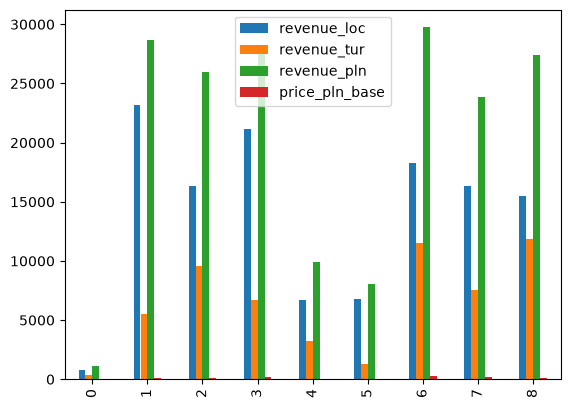

In [91]:
t1.plot.bar()

<Axes: >

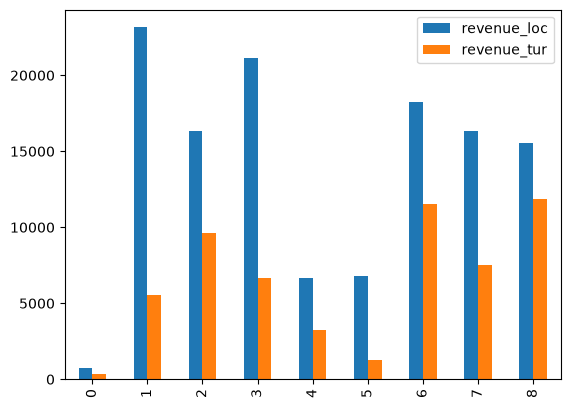

In [92]:
t1[["revenue_loc", "revenue_tur"]].plot.bar()

<Axes: >

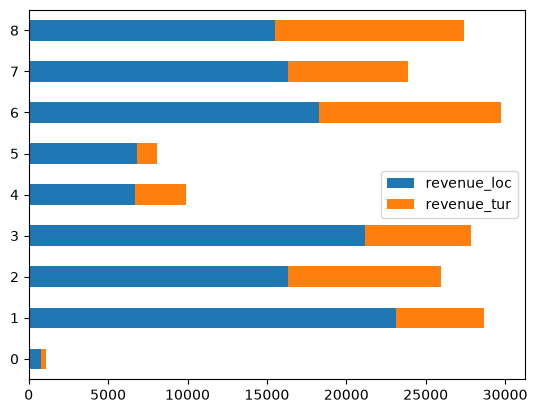

In [93]:
t1[["revenue_loc", "revenue_tur"]].plot.barh(stacked=True)

Minimalny wykres

<BarContainer object of 9 artists>

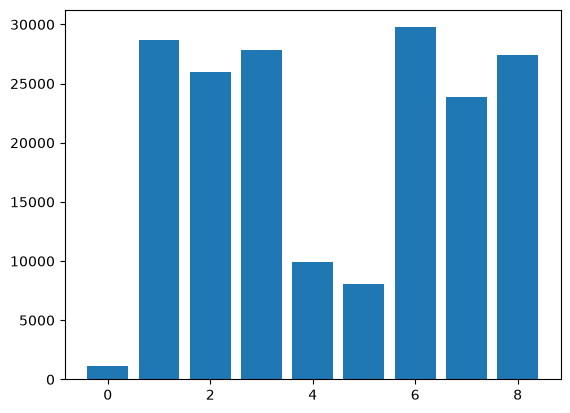

In [94]:
heights = t1["revenue_pln"]
plt.bar(range(len(heights)), heights)

Jawne tworzenie i wyświetlanie wykresu

In [95]:
heights = t1["revenue_pln"]
categories = t1["category"]

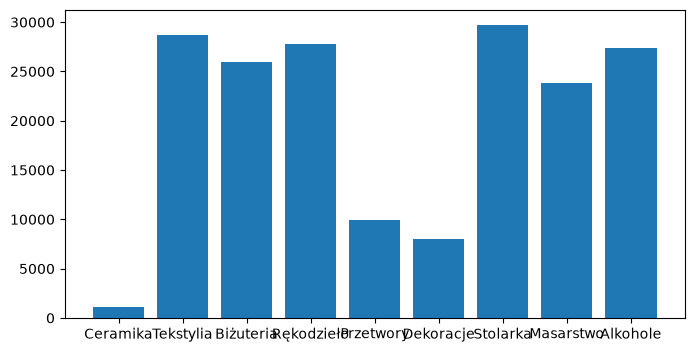

In [96]:
plt.figure(figsize=(8, 4))
plt.bar(categories, heights)
plt.show()

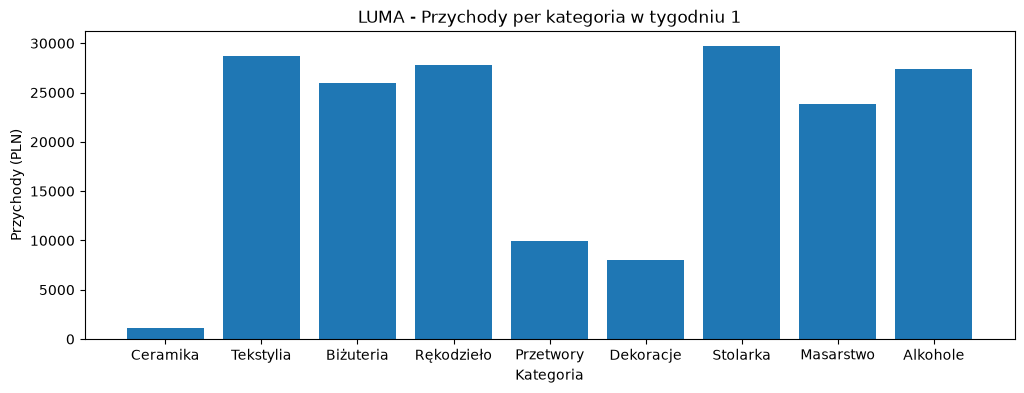

In [97]:
plt.figure(figsize=(12, 4))
plt.bar(categories, heights)
plt.title("LUMA - Przychody per kategoria w tygodniu 1")
plt.xlabel("Kategoria")
plt.ylabel("Przychody (PLN)")
plt.show()

Etykiety wartości i formatowanie liczb

In [98]:
def format_pln(x: float) -> str:
    return f"{int(round(x)):,} zł".replace(",","\u202f")

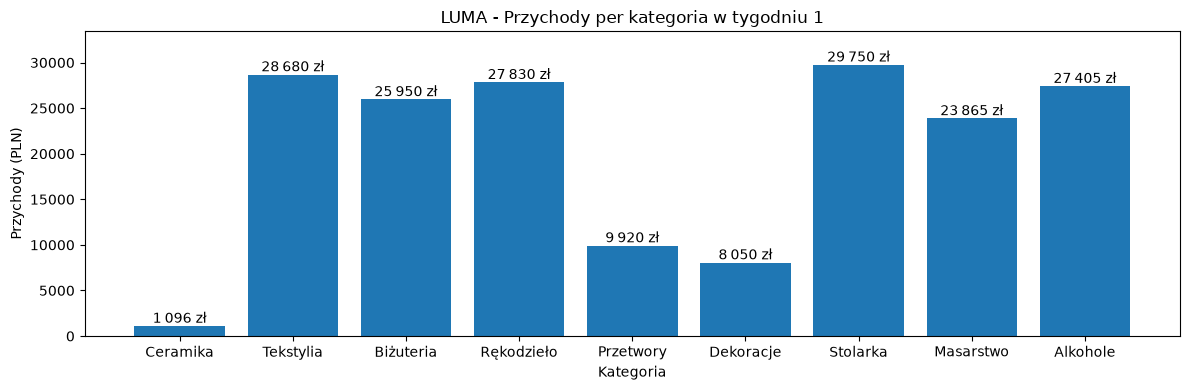

In [99]:
plt.figure(figsize=(12, 4))
bars = plt.bar(categories, heights)
ymin, ymax = plt.ylim()         # pobieranie wartości min i max dla y
pad = (ymax - ymin) * 0.07
plt.ylim(ymin,ymax + pad) #ustawienie nowej wartości y max
for bar in bars:
    x = bar.get_x() + bar.get_width() / 2 
    y = bar.get_height()
    plt.text(x,y, format_pln(y), ha ='center', va = 'bottom')
plt.title("LUMA - Przychody per kategoria w tygodniu 1")
plt.xlabel("Kategoria")
plt.ylabel("Przychody (PLN)")
plt.tight_layout()
plt.show()

In [100]:
def pad_axis(factor=0.07):
    ymin, ymax = plt.ylim() # pobranie wartości min i max dla y
    pad = (ymax - ymin) * factor
    plt.ylim(ymin, ymax + pad) # ustawienie nowej wartości y max

In [101]:
def label_bars_pln(bars):
    for bar in bars:
        x = bar.get_x() + bar.get_width() / 2
        y = bar.get_height()
        plt.text(x, y, format_pln(y), ha="center", va="bottom")

Fromatowanie etykiet podziałki osi

In [102]:
def format_tys(x: float, decimals: int = 0) -> str:
    v = x / 1000.0
    if decimals == 0:
        s = f"{int(round(v)):,}".replace(",", "\u202f")
    else:
        s = f"{v:,.{decimals}f}".replace(",", "\u202f").replace(".", ",")
    return s + " tys."

In [103]:
def format_mln(x: float, decimals: int = 0) -> str:
    v = x / 1000000.0
    if decimals == 0:
        s = f"{int(round(v)):,}".replace(",", "\u202f")
    else:
        s = f"{v:,.{decimals}f}".replace(",", "\u202f").replace(".", ",")
    return s + " mln."

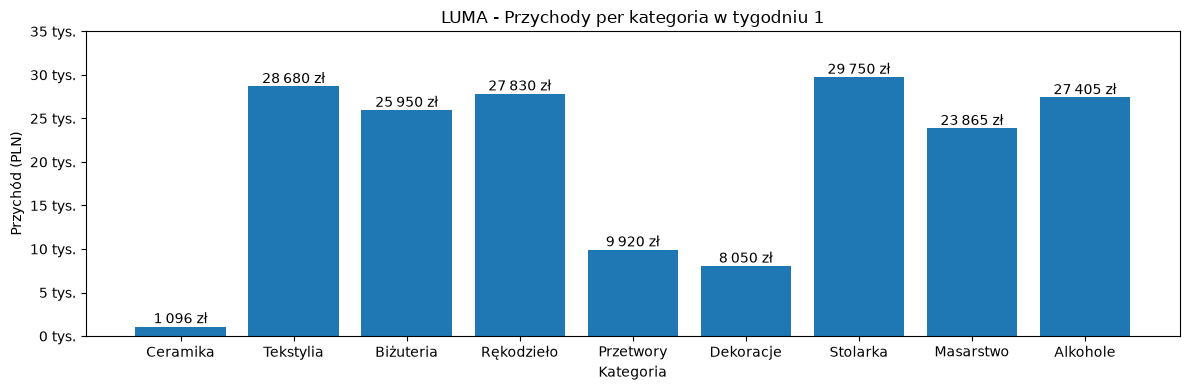

In [104]:
plt.figure(figsize=(12, 4))
bars = plt.bar(categories, heights)
pad_axis()
label_bars_pln(bars)
ypos, ylab_old = plt.yticks()
ylab_new = [format_tys(y) for y in ypos]
plt.yticks(ypos, ylab_new)
plt.title("LUMA - Przychody per kategoria w tygodniu 1")
plt.xlabel("Kategoria")
plt.ylabel("Przychód (PLN)")
plt.tight_layout()
plt.show()

In [105]:
def format_ytics_tys():
    ypos, _ = plt.yticks()
    ylab_new = [format_tys(y) for y in ypos]
    plt.yticks(ypos, ylab_new)

Sortowanie kategorii dla łatwiejszego porównania

In [106]:
t1_sorted = t1.sort_values("revenue_pln", ascending=False).reset_index()
categories = t1_sorted["category"]
heights = t1_sorted["revenue_pln"]

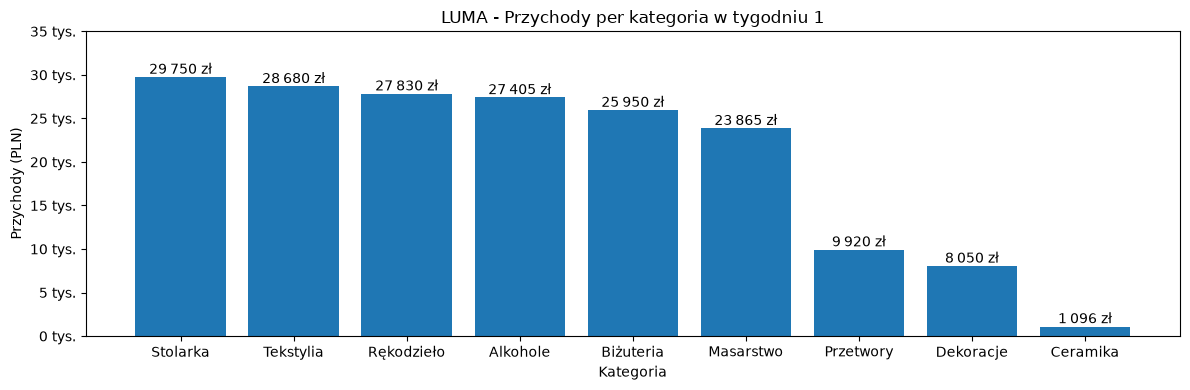

In [107]:
plt.figure(figsize=(12, 4))
bars = plt.bar(categories, heights)
pad_axis()
label_bars_pln(bars)
format_ytics_tys()
plt.yticks(ypos, ylab_new)
plt.title("LUMA - Przychody per kategoria w tygodniu 1")
plt.xlabel("Kategoria")
plt.ylabel("Przychody (PLN)")
plt.tight_layout()
plt.show()

Siatka w tle wykresu

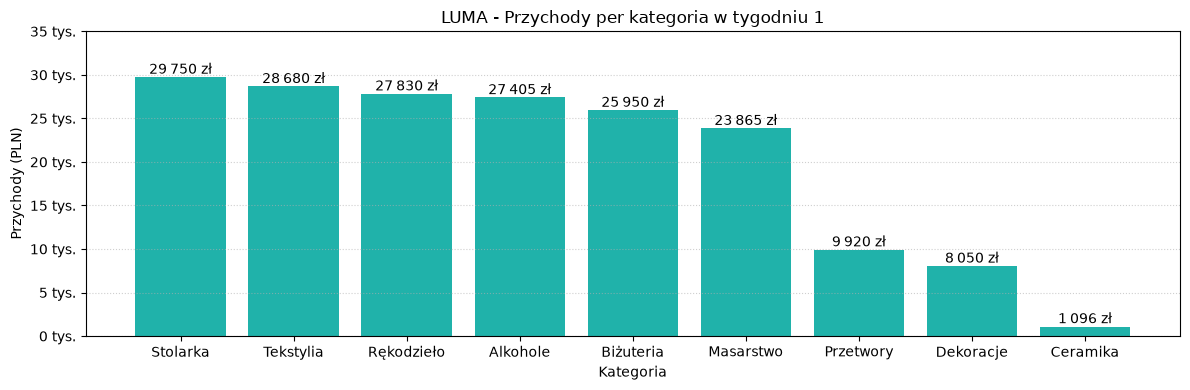

In [108]:
plt.figure(figsize=(12, 4))
bars = plt.bar(categories, heights, color = 'lightseagreen')
pad_axis()
label_bars_pln(bars)
format_ytics_tys()
plt.grid(axis = 'y', linestyle=":", alpha = 0.6)
plt.title("LUMA - Przychody per kategoria w tygodniu 1")
plt.xlabel("Kategoria")
plt.ylabel("Przychody (PLN)")
plt.tight_layout()
plt.show()

## Analiza i wizualizacja danych - 2 serie danych

### Wygenerowanie danych tygodniowych dla tygodnia 2

Mini-festiwal przyciąga klientów: lokalni +13%, turyści +20%

In [109]:
boost_loc = 0.13
boost_tur = 0.20

t2 = generate_weekly_data(catalog, rng, boost_loc=boost_loc, boost_tur=boost_tur)
t2 = t2.merge(catalog[["category", "price_pln_base"]], on="category", how = "left") 
print("Tydzień 2 - przychody per kategoria (PLN)")
display(t2)
print("Łączne przychody w tygodniu 1: ", format_pln(t1["revenue_pln"].sum()))
print("Łączne przychody w tygodniu 2: ", format_pln(t2["revenue_pln"].sum()))

Tydzień 2 - przychody per kategoria (PLN)


,category,revenue_loc,revenue_tur,revenue_pln,price_pln_base
0,Ceramika,1088,680,1768,8
1,Tekstylia,25320,6480,31800,120
2,Biżuteria,20700,16650,37350,150
3,Rękodzieło,24150,9660,33810,230
4,Przetwory,6560,4800,11360,40
5,Dekoracje,4375,1155,5530,35
6,Stolarka,21750,10750,32500,250
7,Masarstwo,15910,7955,23865,215
8,Alkohole,19170,9315,28485,135


Łączne przychody w tygodniu 1:  182 546 zł
Łączne przychody w tygodniu 2:  206 468 zł


Przygotowanie danych do wykresów

In [110]:
categories = t1_sorted["category"]
t1_revenue_total = t1_sorted["revenue_pln"]
t2_revenue_total = t2.set_index("category").loc[categories]["revenue_pln"]   # dopasowanie
x_locs = np.arange(len(categories))
bar_width = 0.4
bar_half = bar_width / 2 

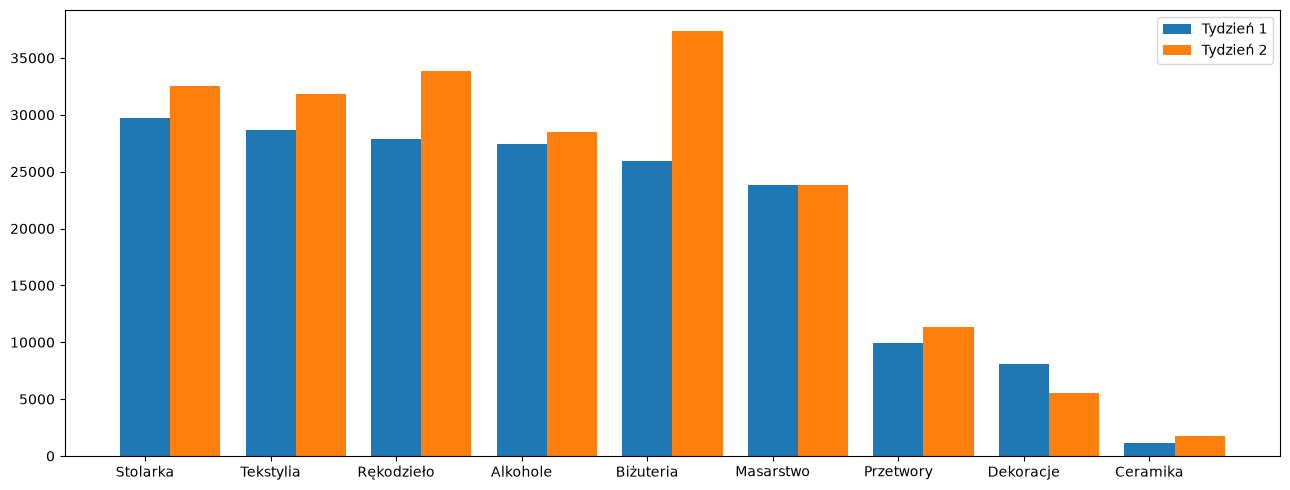

In [111]:
plt.figure(figsize=(13,5))
plt.bar(x_locs-bar_half, t1_revenue_total, width = bar_width, label = "Tydzień 1", tick_label=categories)
plt.bar(x_locs+bar_half, t2_revenue_total, width = bar_width, label = "Tydzień 2")
plt.legend()
plt.tight_layout()
plt.show()

### Łączne operowanie na seriach

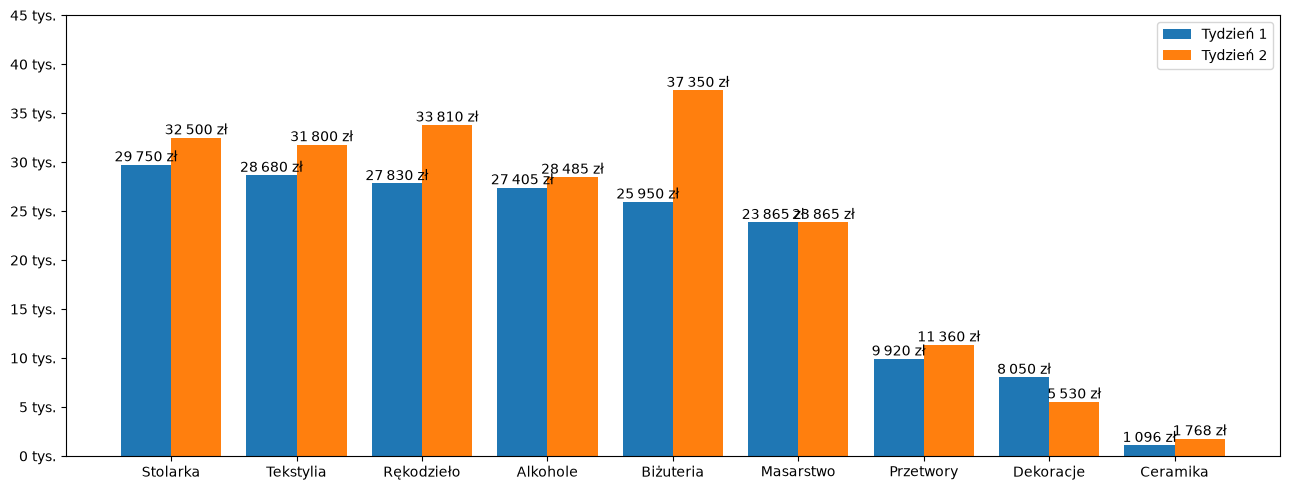

In [112]:
plt.figure(figsize=(13,5))
bars_1 = plt.bar(x_locs-bar_half, t1_revenue_total, width = bar_width, label = "Tydzień 1", tick_label=categories)
bars_2 = plt.bar(x_locs+bar_half, t2_revenue_total, width = bar_width, label = "Tydzień 2")
plt.xticks(x_locs, categories) 
pad_axis()
label_bars_pln(chain(bars_1, bars_2))               #????? nie działa
format_ytics_tys()

plt.legend()
plt.tight_layout()
plt.show()

In [113]:
def format_sep(x: float) -> str:
    return f"{int(round(x)):,}".replace(",","\u202f")

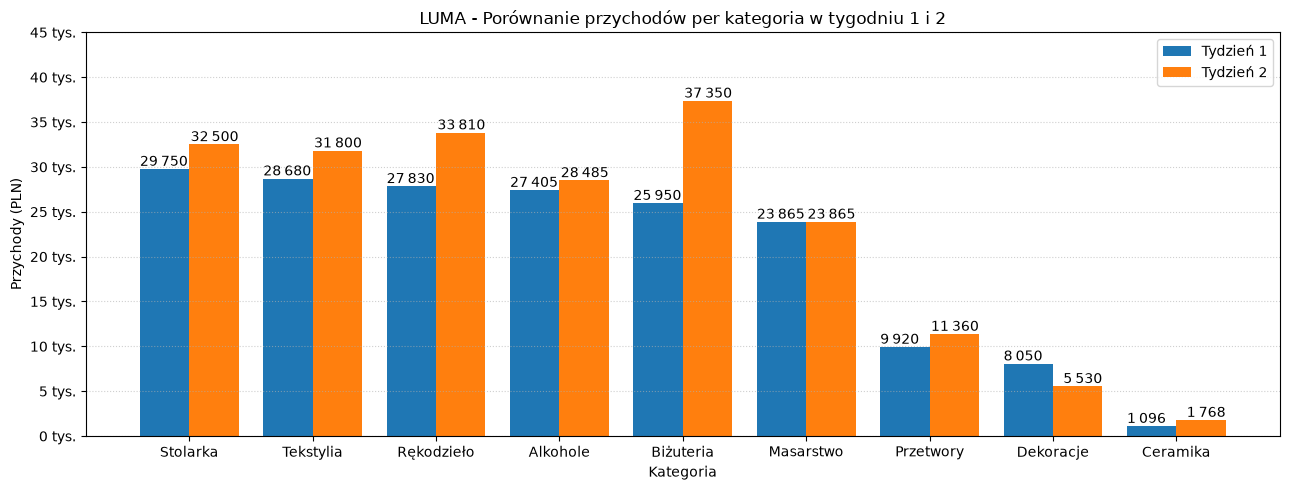

In [114]:
plt.figure(figsize=(13,5))
bars_1 = plt.bar(x_locs-bar_half, t1_revenue_total, width = bar_width, label = "Tydzień 1", tick_label=categories)
bars_2 = plt.bar(x_locs+bar_half, t2_revenue_total, width = bar_width, label = "Tydzień 2")
plt.xticks(x_locs, categories) 
pad_axis()

for b in bars_1:
    x,y = b.get_x(), b.get_height()
    plt.text(x,y, format_sep(y), ha="left", va="bottom")


for b in bars_2:
    x,y = b.get_x() + b.get_width(), b.get_height()
    plt.text(x,y, format_sep(y), ha="right", va="bottom")


format_ytics_tys()

plt.grid(axis = 'y', linestyle=":", alpha = 0.6)
plt.title("LUMA - Porównanie przychodów per kategoria w tygodniu 1 i 2")
plt.xlabel("Kategoria")
plt.ylabel("Przychody (PLN)")

plt.legend()
plt.tight_layout()
plt.show()

## Analiza i wizualizacja danych - prezentacja zmian bezwględnych

Przygotowanie różnic i procentowych zmian między tygodniami 1 i 2

In [115]:
order = CATEGORIES
t1_revenue_total = t1.set_index("category").loc[order]["revenue_pln"]
t2_revenue_total = t2.set_index("category").loc[order]["revenue_pln"]

base = t1_revenue_total
delta = t2_revenue_total - t1_revenue_total

pct = np.divide(
    delta,
    base,
    out=np.full_like(base, np.nan, dtype=float), 
    where=base !=0
) *100

t_delta = pd.DataFrame({
    "category": order,
    "t1_pln": t1_revenue_total.astype(int),
    "t2_pln": t2_revenue_total.astype(int),
    "delta_pln": delta.astype(int),
    "delta_pct": np.round(pct, 1)
}).reset_index(drop=True)

display(t_delta)

,category,t1_pln,t2_pln,delta_pln,delta_pct
0,Ceramika,1096,1768,672,61.3
1,Tekstylia,28680,31800,3120,10.9
2,Biżuteria,25950,37350,11400,43.9
3,Rękodzieło,27830,33810,5980,21.5
4,Przetwory,9920,11360,1440,14.5
5,Dekoracje,8050,5530,-2520,-31.3
6,Stolarka,29750,32500,2750,9.2
7,Masarstwo,23865,23865,0,0.0
8,Alkohole,27405,28485,1080,3.9


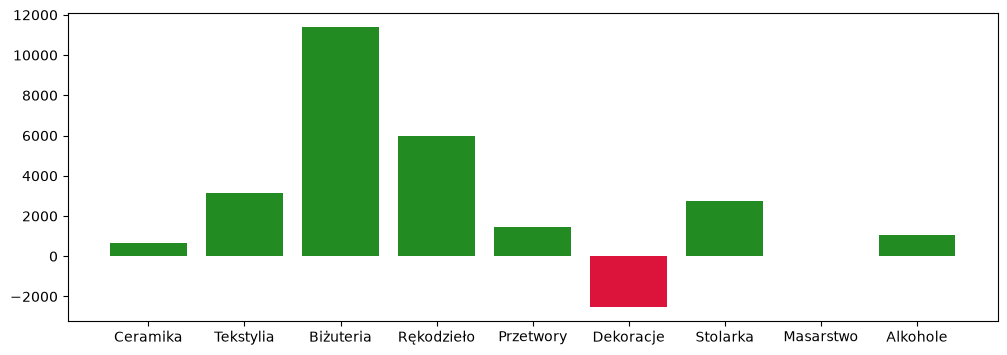

In [116]:
colors = ["forestgreen" if v >= 0 else "crimson" for v in t_delta['delta_pln']]
plt.figure(figsize=(12,4))
plt.bar(t_delta["category"], t_delta["delta_pln"], color = colors)
plt.show()

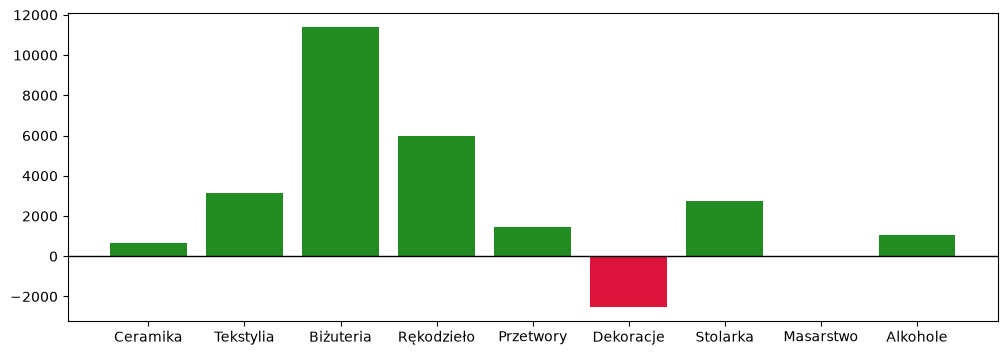

In [119]:
colors = ["forestgreen" if v >= 0 else "crimson" for v in t_delta['delta_pln']]
plt.figure(figsize=(12,4))
plt.bar(t_delta["category"], t_delta["delta_pln"], color = colors)
plt.axhline(0, color ="black", linewidth=1)
plt.show()

In [ ]:
def format_sep_signed(x:float) -> str:
    s = format_sep((abs(x)))
    return("+" if x>=0 else "\u2212") + s

In [ ]:
def pad_ylims(axes, factor=0.07):
    ymin, ymax = axes.get_ylim()  # pobranie wartości min i max dla y
    pad = (ymax - ymin) * factor
    plt.ylim(ymin - pad, ymax + pad) # ustawienie nowej wartości y max


In [122]:
def label_bars(axes, bars, values, formatter = format_sep_signed, offset_factor=0.02):
    ymin, ymax, axes.get_ylim()
    offset = (ymax - ymin) * offset_factor
    
    for b, v, in zip(bars, values):
        x = b.get_x() + b.get_width() / 2
        y = b.get_y() + b.get_height()
        label = formatter(y)
        va = "top" if v < 0 else "bottom"
        y_text = y - offset if v < 0 else y + offset 
        axes.text(x,y_text, label, ha = 'center', va=va)

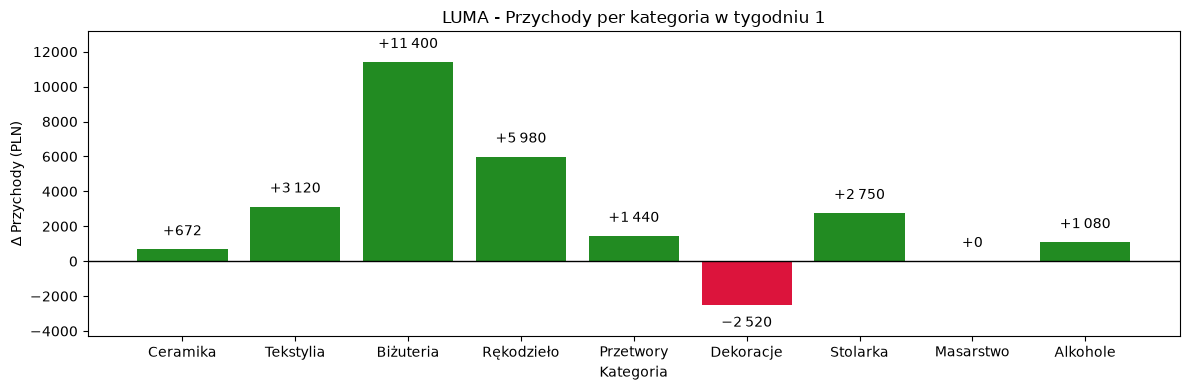

In [123]:
plt.figure(figsize = (12,4))
bars = plt.bar(t_delta["category"], t_delta["delta_pln"], color=colors)
pad_ylims(plt.gca())
label_bars(plt.gca(), bars, t_delta["delta_pln"])
plt.axhline(0, color = 'black', linewidth =1)
plt.title("LUMA - Przychody per kategoria w tygodniu 1")
plt.xlabel("Kategoria")
plt.ylabel("\u2206 Przychody (PLN)")
plt.tight_layout()
plt.show()
